# COPUS Classroom Activity Time Analysis

This notebook examines the distribution of student and instructor
activities across COPUS classroom observations.

Each observation interval represents two minutes of classroom time.
Multiple activity codes may be recorded within the same interval.

Analysis objectives:
- Quantify the observed duration and frequency of COPUS activities.
- Compare student and instructor activity patterns.
- Examine activity distributions across courses and observations.

### Step 1: Load and inspect the processed data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

data_path = Path("../data/processed/copus_intervals.parquet")

df = pd.read_parquet(data_path)

student_codes = [
    col for col in df.columns
    if col.startswith("student_")
]

instructor_codes = [
    col for col in df.columns
    if col.startswith("instructor_")
]

engagement_codes = [
    col for col in df.columns
    if col.startswith("engagement_")
]

print("Dataset shape:", df.shape)
print("Observation forms:", df["file"].nunique())
print("Unique courses:", df["course_id"].nunique())

print("\nCOPUS code categories:")
print("Student codes:", len(student_codes))
print("Instructor codes:", len(instructor_codes))
print("Engagement codes:", len(engagement_codes))

Dataset shape: (819, 40)
Observation forms: 24
Unique courses: 10

COPUS code categories:
Student codes: 13
Instructor codes: 12
Engagement codes: 3


### Step 2: Calculate activity frequency and observed duration

In [2]:
code_columns = (
    student_codes +
    instructor_codes +
    engagement_codes
)

activity_summary = pd.DataFrame({
    "interval_count": df[code_columns].sum(),
    "observed_minutes": df[code_columns].sum() * 2,
    "interval_pct": df[code_columns].mean() * 100
})

activity_summary["category"] = (
    activity_summary.index.str.split("_").str[0]
)

activity_summary = (
    activity_summary
    .sort_values(
        ["category", "interval_count"],
        ascending=[True, False]
    )
)

activity_summary.index.name = "COPUS code"

display(activity_summary.round(1))

,interval_count,observed_minutes,interval_pct,category
COPUS code,,,,
engagement_L,315,630,38.5,engagement
engagement_H,240,480,29.3,engagement
engagement_M,231,462,28.2,engagement
instructor_Lec,360,720,44.0,instructor
instructor_MG,186,372,22.7,instructor
instructor_1o1,172,344,21.0,instructor
instructor_PQ,168,336,20.5,instructor
instructor_W,98,196,12.0,instructor
instructor_D/V,82,164,10.0,instructor


### Step 3: Visualize student and instructor activity frequencies

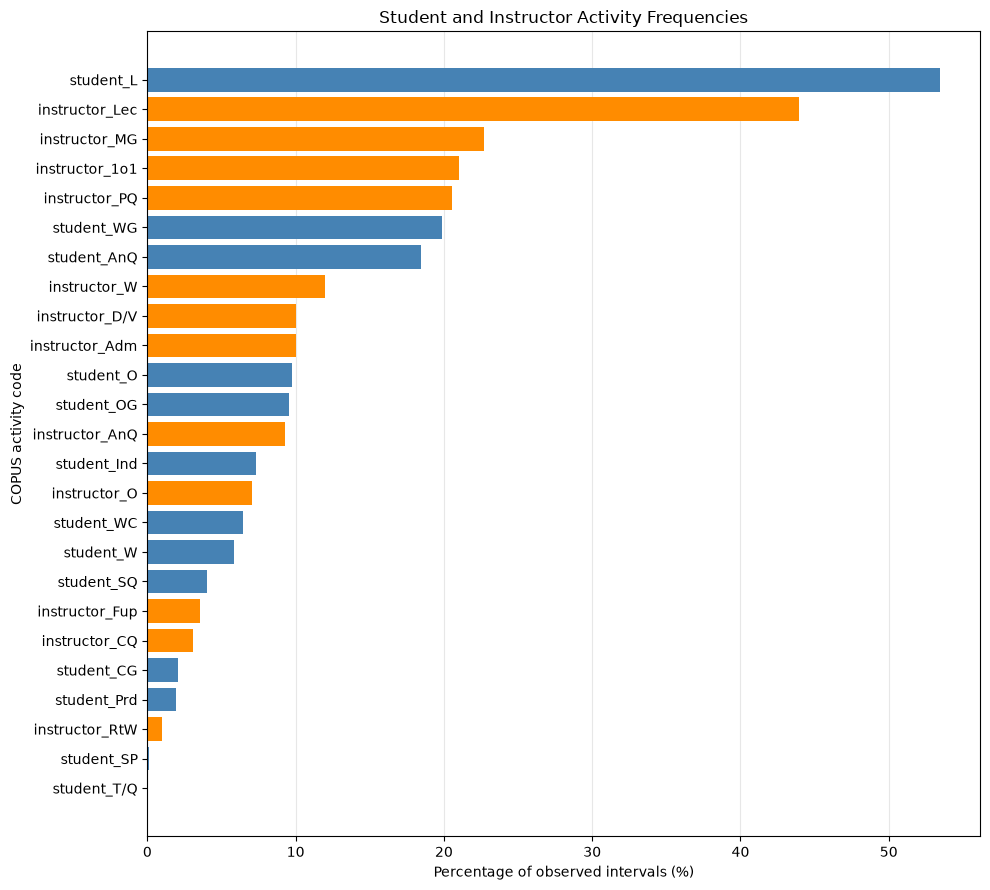

In [3]:
activity_plot = (
    activity_summary[
        activity_summary["category"].isin(
            ["student", "instructor"]
        )
    ]
    .sort_values("interval_pct")
)

fig, ax = plt.subplots(figsize=(10, 9))

colors = [
    "steelblue" if category == "student" else "darkorange"
    for category in activity_plot["category"]
]

ax.barh(
    activity_plot.index,
    activity_plot["interval_pct"],
    color=colors
)

ax.set_xlabel("Percentage of observed intervals (%)")
ax.set_ylabel("COPUS activity code")
ax.set_title("Student and Instructor Activity Frequencies")

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Step 4: Calculate activity frequencies by course

In [4]:
activity_codes = student_codes + instructor_codes

course_activity = (
    df.groupby("course_id")[activity_codes]
      .mean()
      .mul(100)
)

display(course_activity.round(1).T)

course_id,BLAW 3430.002,BLAW 3430.004,CHEM 1410.254,CHEM 1410.255,INFO 5000,INFO 5307.220,INFO 5307.221,MUMH 3510,MUMH 3510.001,MUMH 3510.203
student_L,83.6,97.5,10.0,0.8,33.1,84.2,79.6,82.0,60.5,48.0
student_Ind,0.0,0.0,5.7,12.5,9.0,0.0,0.0,28.0,15.8,6.0
student_CG,0.0,1.3,1.4,1.7,2.3,0.0,1.1,8.0,6.6,0.0
student_WG,0.0,0.0,78.6,80.0,0.8,0.0,0.0,2.0,0.0,20.0
student_OG,0.0,0.0,4.3,2.5,30.8,0.0,0.0,24.0,23.7,2.0
student_AnQ,30.0,35.4,1.4,0.0,7.5,26.3,24.7,34.0,30.3,12.0
student_SQ,13.6,2.5,0.0,0.0,5.3,2.6,0.0,6.0,6.6,0.0
student_WC,0.9,3.8,0.0,1.7,26.3,0.0,5.4,4.0,5.3,2.0
student_Prd,0.0,0.0,0.0,0.8,0.0,0.0,0.0,30.0,0.0,0.0
student_SP,0.0,0.0,0.0,0.0,0.8,0.0,0.0,0.0,0.0,0.0


### Step 5: Visualize course-level activity patterns

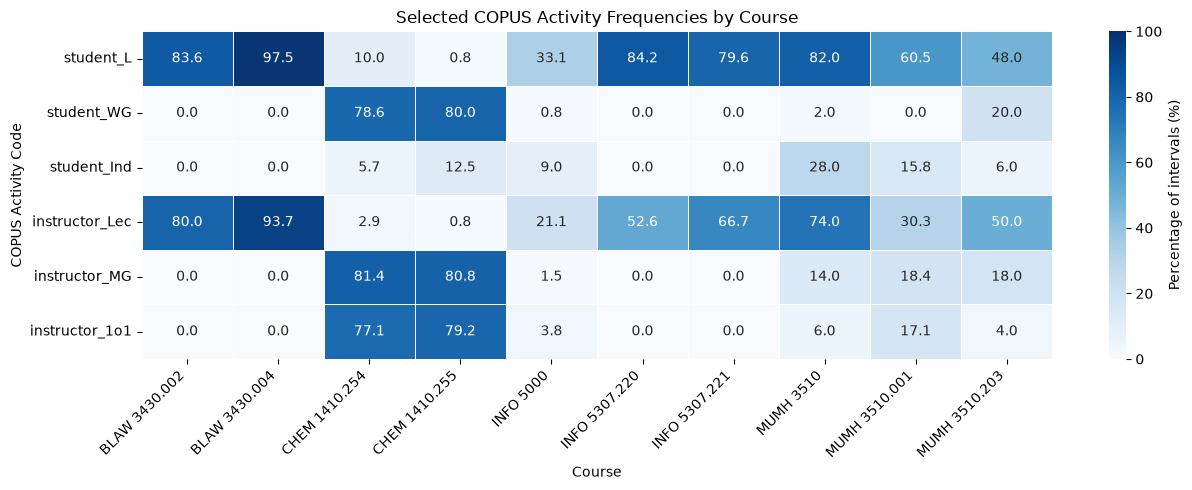

In [5]:
import seaborn as sns

selected_codes = [
    "student_L",
    "student_WG",
    "student_Ind",
    "instructor_Lec",
    "instructor_MG",
    "instructor_1o1"
]

selected_activity = course_activity[selected_codes].T

plt.figure(figsize=(13, 5))

sns.heatmap(
    selected_activity,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Percentage of intervals (%)"}
)

plt.title("Selected COPUS Activity Frequencies by Course")
plt.xlabel("Course")
plt.ylabel("COPUS Activity Code")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### Step 6: Examine variation across observation sessions

In [6]:
session_activity = (
    df.groupby(
        ["course_id", "observation_date", "file", "observer"]
    )[selected_codes]
    .mean()
    .mul(100)
    .reset_index()
)

session_activity = session_activity.sort_values(
    ["course_id", "observation_date", "observer"]
)

display(session_activity.round(1))

C:\Users\tjt0147\AppData\Local\Temp\ipykernel_11340\120173391.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(session_activity.round(1))


,course_id,observation_date,file,observer,student_L,student_WG,student_Ind,instructor_Lec,instructor_MG,instructor_1o1
0,BLAW 3430.002,2026-09-21,COPUS-form-BLAW 3430.002_20260921.xlsx,Rainie Yu,95.0,0.0,0.0,92.5,0.0,0.0
1,BLAW 3430.002,2026-09-28,COPUS-form-BLAW3430.002 09282026.xlsx,Tania Heap,53.3,0.0,0.0,50.0,0.0,0.0
2,BLAW 3430.002,2026-10-05,COPUS-form-BLAW 3430.002_10_5_26.xlsx,Natalie Brown,95.0,0.0,0.0,90.0,0.0,0.0
4,BLAW 3430.004,2026-09-22,COPUS-form_BLAW3430.004 09222026 AKR.xlsx,Amy Petros,100.0,0.0,0.0,92.3,0.0,0.0
3,BLAW 3430.004,2026-09-22,COPUS-form-BLAW 3430.004_20260922.xlsx,Rainie Yu,95.0,0.0,0.0,95.0,0.0,0.0
5,CHEM 1410.254,2026-08-26,COPUS-form_CHEM1410.254_9_16_2026.xlsx,Natalie Brown,12.5,77.5,0.0,0.0,82.5,77.5
6,CHEM 1410.254,2026-09-23,COPUS-form-CHEM1410.254_9_23_2026.xlsx,"Trebat, Thomas",6.7,80.0,13.3,6.7,80.0,76.7
7,CHEM 1410.255,2026-09-16,COPUS-form_CHEM1410.255_9_16_2026.xlsx,Natalie Brown,0.0,82.5,0.0,0.0,85.0,80.0
8,CHEM 1410.255,2026-09-23,COPUS-form_CHEM1410.255_9_23_2026.xlsx,Natalie Brown,0.0,75.0,20.0,2.5,72.5,72.5
9,CHEM 1410.255,2026-09-30,COPUS-form_CHEM1410.255_9_30_2026.xlsx,Natalie Brown,2.5,82.5,17.5,0.0,85.0,85.0


### Step 7: Quantify session-to-session variability

In [7]:
course_variability = (
    session_activity
    .groupby("course_id")[selected_codes]
    .agg(["mean", "std", "count"])
)

display(course_variability.round(1))

student_L             student_WG             student_Ind        \
                   mean   std count       mean   std count        mean   std   
course_id                                                                      
BLAW 3430.002      81.1  24.1     3        0.0   0.0     3         0.0   0.0   
BLAW 3430.004      97.5   3.5     2        0.0   0.0     2         0.0   0.0   
CHEM 1410.254       9.6   4.1     2       78.8   1.8     2         6.7   9.4   
CHEM 1410.255       0.8   1.4     3       80.0   4.3     3        12.5  10.9   
INFO 5000          33.1  28.0     4        0.7   1.4     4         9.5  12.6   
INFO 5307.220      84.2   NaN     1        0.0   NaN     1         0.0   NaN   
INFO 5307.221      79.4   5.5     2        0.0   0.0     2         0.0   0.0   
MUMH 3510          82.0   8.5     2        2.0   2.8     2        28.0  33.9   
MUMH 3510.001      60.3  16.5     3        0.0   0.0     3        15.5  17.6   
MUMH 3510.203      48.0  22.6     2       20.0  11.3     2         6.0   8.5   

                    instructor_Lec             instructor_MG              \
              count           mean   std count          mean   std count   
course_id                                                                  
BLAW 3430.002     3           77.5  23.8     3           0.0   0.0     3   
BLAW 3430.004     2           93.7   1.9     2           0.0   0.0     2   
CHEM 1410.254     2            3.3   4.7     2          81.2   1.8     2   
CHEM 1410.255     3            0.8   1.4     3          80.8   7.2     3   
INFO 5000         4           20.5  17.8     4           1.7   3.3     4   
INFO 5307.220     1           52.6   NaN     1           0.0   NaN     1   
INFO 5307.221     2           66.5   6.1     2           0.0   0.0     2   
MUMH 3510         2           74.0   2.8     2          14.0   2.8     2   
MUMH 3510.001     3           30.5  16.4     3          18.5  20.2     3   
MUMH 3510.203     2           50.0  14.1     2          18.0   2.8     2   

              instructor_1o1              
                        mean   std count  
course_id                                 
BLAW 3430.002            0.0   0.0     3  
BLAW 3430.004            0.0   0.0     2  
CHEM 1410.254           77.1   0.6     2  
CHEM 1410.255           79.2   6.3     3  
INFO 5000                3.9   3.0     4  
INFO 5307.220            0.0   NaN     1  
INFO 5307.221            0.0   0.0     2  
MUMH 3510                6.0   8.5     2  
MUMH 3510.001           17.3  18.0     3  
MUMH 3510.203            4.0   0.0     2

### Step 8: Visualize session-level variation

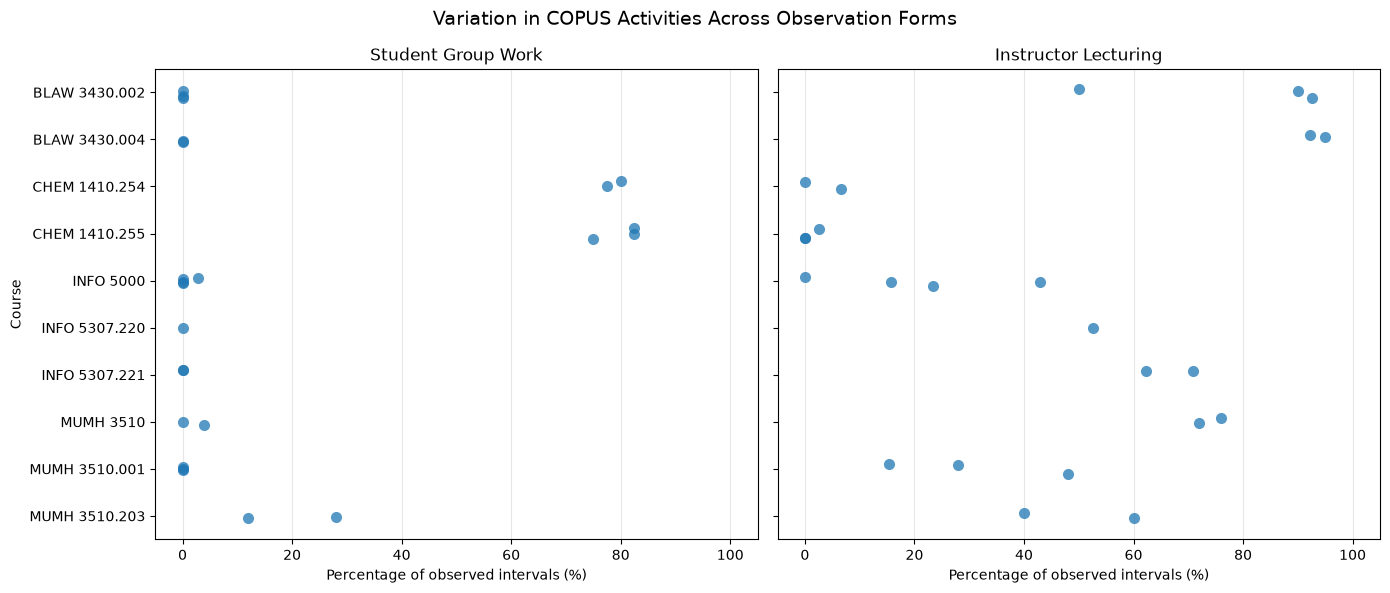

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

plot_codes = [
    ("student_WG", "Student Group Work"),
    ("instructor_Lec", "Instructor Lecturing")
]

for ax, (code, title) in zip(axes, plot_codes):
    sns.stripplot(
        data=session_activity,
        x=code,
        y="course_id",
        ax=ax,
        size=8,
        jitter=0.12,
        alpha=0.75
    )

    ax.set_title(title)
    ax.set_xlabel("Percentage of observed intervals (%)")
    ax.set_ylabel("Course")
    ax.set_xlim(-5, 105)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

plt.suptitle(
    "Variation in COPUS Activities Across Observation Forms",
    fontsize=14
)

plt.tight_layout()
plt.show()

#### Step 8a: Create a combined student group work indicator

In [9]:
group_codes = [
    "student_CG",
    "student_WG",
    "student_OG"
]

df["student_group_work"] = (
    df[group_codes]
    .eq(1)
    .any(axis=1)
    .astype(int)
)

group_work_summary = (
    df.groupby("course_id")["student_group_work"]
    .agg(
        interval_count="sum",
        total_intervals="count",
        group_work_pct=lambda x: x.mean() * 100
    )
)

display(group_work_summary.round(1))

,interval_count,total_intervals,group_work_pct
course_id,,,
BLAW 3430.002,0,110,0.0
BLAW 3430.004,1,79,1.3
CHEM 1410.254,56,70,80.0
CHEM 1410.255,98,120,81.7
INFO 5000,44,133,33.1
INFO 5307.220,0,38,0.0
INFO 5307.221,1,93,1.1
MUMH 3510,17,50,34.0
MUMH 3510.001,22,76,28.9


#### Step 8b: Update the session-level comparison

In [10]:
session_group_work = (
    df.groupby(
        ["course_id", "observation_date", "file", "observer"]
    )["student_group_work"]
    .mean()
    .mul(100)
    .reset_index(name="student_group_work")
)

session_activity = session_activity.merge(
    session_group_work,
    on=["course_id", "observation_date", "file", "observer"],
    how="left",
    validate="one_to_one"
)

display(
    session_activity[
        ["course_id", "observation_date",
         "observer", "student_group_work", "instructor_Lec"]
    ].round(1)
)

C:\Users\tjt0147\AppData\Local\Temp\ipykernel_11340\2076426008.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(1)


,course_id,observation_date,observer,student_group_work,instructor_Lec
0,BLAW 3430.002,2026-09-21,Rainie Yu,0.0,92.5
1,BLAW 3430.002,2026-09-28,Tania Heap,0.0,50.0
2,BLAW 3430.002,2026-10-05,Natalie Brown,0.0,90.0
3,BLAW 3430.004,2026-09-22,Amy Petros,2.6,92.3
4,BLAW 3430.004,2026-09-22,Rainie Yu,0.0,95.0
5,CHEM 1410.254,2026-08-26,Natalie Brown,80.0,0.0
6,CHEM 1410.254,2026-09-23,"Trebat, Thomas",80.0,6.7
7,CHEM 1410.255,2026-09-16,Natalie Brown,87.5,0.0
8,CHEM 1410.255,2026-09-23,Natalie Brown,75.0,2.5
9,CHEM 1410.255,2026-09-30,Natalie Brown,82.5,0.0


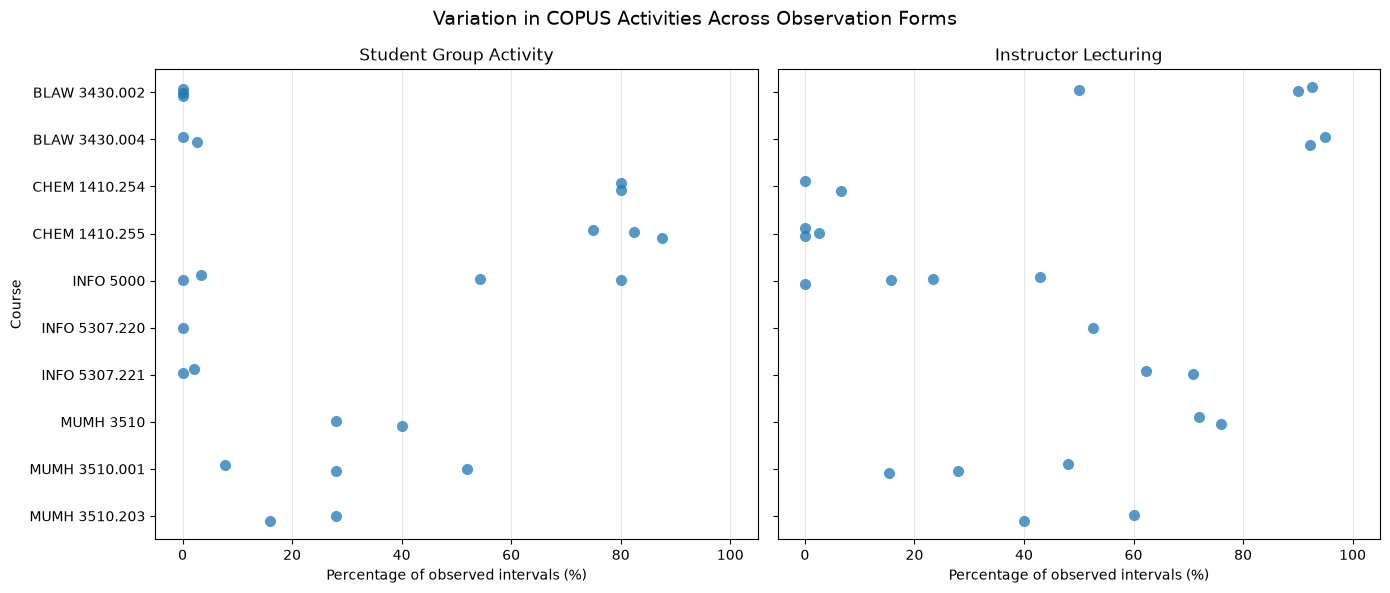

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

plot_codes = [
    ("student_group_work", "Student Group Activity"),
    ("instructor_Lec", "Instructor Lecturing")
]

for ax, (code, title) in zip(axes, plot_codes):
    sns.stripplot(
        data=session_activity,
        x=code,
        y="course_id",
        ax=ax,
        size=8,
        jitter=0.12,
        alpha=0.75
    )

    ax.set_title(title)
    ax.set_xlabel("Percentage of observed intervals (%)")
    ax.set_ylabel("Course")
    ax.set_xlim(-5, 105)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

plt.suptitle(
    "Variation in COPUS Activities Across Observation Forms",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Step 9: Examine the relationship between group activity and lecturing

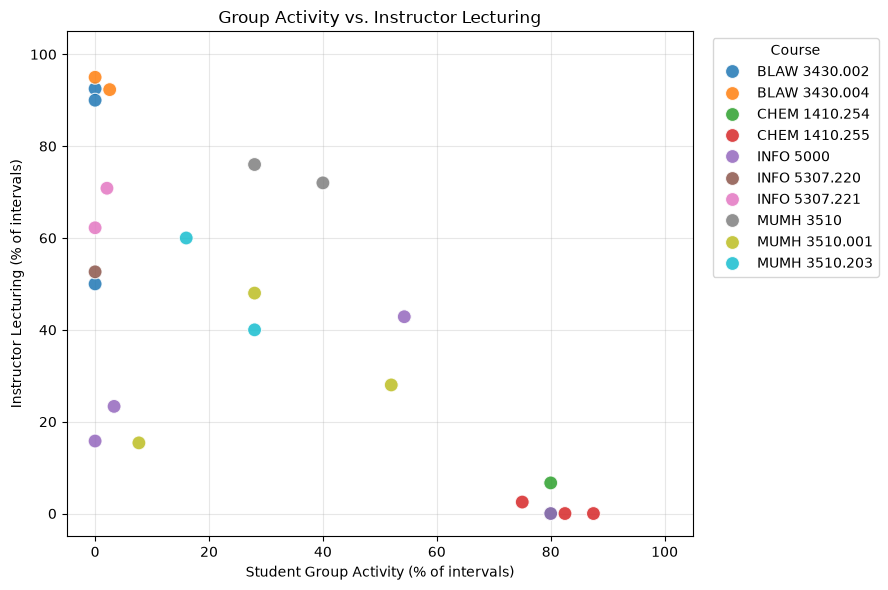

In [12]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=session_activity,
    x="student_group_work",
    y="instructor_Lec",
    hue="course_id",
    s=100,
    alpha=0.85,
    ax=ax
)

ax.set_xlabel("Student Group Activity (% of intervals)")
ax.set_ylabel("Instructor Lecturing (% of intervals)")
ax.set_title("Group Activity vs. Instructor Lecturing")

ax.set_xlim(-5, 105)
ax.set_ylim(-5, 105)

ax.grid(alpha=0.3)
ax.set_axisbelow(True)

ax.legend(
    title="Course",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()